# Phi mirror symmetry on narrow wedges

The closed shell of `decks/shell_sp.athinput` at rest and spherically symmetric (no rotation, no
lateral mode), with the production Gauss-Legendre 7 x 18 ray set (azimuthal period 20 deg), 8 cycles:
a 20 deg wedge (exact phi-wall maps, no key) and 3.7 and 7.3 deg wedges with
`vet_gd_wall_sym = true` (with `vet_gd_wall_interp = true`). A mirror-symmetric state must have a
wedge-mean $F_\phi$ of zero: `fphi` $= |\sum F_\phi| / \sum |F_r|$. The 3.7 deg wedge without the
key must stop with the wedge FATAL.

Criterion: fphi $\le 10^{-8}$ on all three wedges, the FATAL, no `CLEAN WARNING`.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/m1_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.m1t (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/m1_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_m1test/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('M1_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('M1_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10})
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_m1test/src/athena 
runs   runs


In [2]:
TEST = 'wedge_sym'
res = nb.suite(TEST, EXE, WORK, THREADS)

loading the existing run runs/wedge_sym


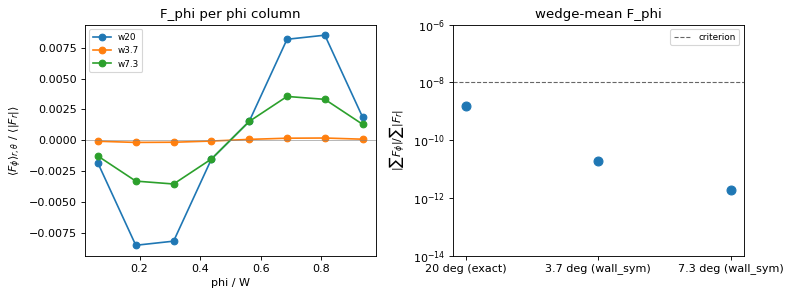

3.7 deg without the key: <rad_m1>/vet_gd: vet_gd_gl_nphi must be >= 4 with 2 pi/nphi dividing the phi period of the wedge (exact wall maps), or vet_gd_wall_sym = true
PASS wedge_sym   criterion {"max": {"fphi": 1e-08}, "equal": {"wedge_fatal": 1, "warnings": 0}}


In [3]:
# F_phi across the narrow wedge: odd about the wedge centre, so its mean vanishes
m1t = nb.m1t
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for tag in ('w20', 'w3.7', 'w7.3'):
    d = os.path.join(WORK, TEST, tag)
    m = m1t.last_bin(d, 'm1')
    f3 = m['m1_f3'].mean(axis=(1, 2))/np.abs(m['m1_f1']).mean()   # theta-r mean per phi column
    ax[0].plot((np.arange(len(f3)) + 0.5)/len(f3), f3, 'o-', label=tag)
ax[0].axhline(0, c='0.5', lw=0.5)
ax[0].set(xlabel='phi / W', ylabel=r'$\langle F_\phi\rangle_{r,\theta}$ / $\langle|F_r|\rangle$', title='F_phi per phi column')
ax[0].legend(fontsize=8)
ax[1].semilogy(range(3), res['fphi'], 'o', ms=8)
ax[1].axhline(1e-8, c='0.4', ls='--', lw=1, label='criterion')
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(['20 deg (exact)', '3.7 deg (wall_sym)', '7.3 deg (wall_sym)'])
ax[1].set(ylabel=r'$|\sum F_\phi| / \sum |F_r|$', ylim=(1e-14, 1e-6), title='wedge-mean F_phi'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
log = open(os.path.join(WORK, TEST, 'w3.7_nosym', 'run.log')).read()
print('3.7 deg without the key:', [l for l in log.splitlines() if 'vet_gd_wall_sym' in l][0])
_ = nb.verdict(TEST, res)